# 18 — Phân phối proxy label và training-readiness

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Proxy label không phải ground truth; không có nhãn hazard đã xác minh hay quyết định human review nào được dùng.

Nhãn ở đây là **out-of-fold**: mỗi cửa sổ Hohai được gắn nhãn bằng ngưỡng fit trên các điều kiện T khác.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/proxy_rules.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/proxy_rules.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
PROXY = REPO_ROOT / "ml/data/labels/proxy_v1"
summary = json.loads((REPO_ROOT / "ml/reports/ml/proxy_dataset_summary.json").read_text())
measurements = pd.read_parquet(PROXY / "measurements.parquet")
labels = pd.read_parquet(PROXY / "proxy_labels_oof.parquet")
data = measurements.merge(labels, on="window_id", validate="one_to_one")
TARGETS = ["RELATIVE_HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH"]
import sklearn
exe = Path(sys.executable)
print("Interpreter:", exe.relative_to(REPO_ROOT) if REPO_ROOT in exe.parents else exe.name, "| scikit-learn", sklearn.__version__)
print("Rule version:", summary["rule_version"], "| cửa sổ:", len(data), "| đủ 23 feature:", int(data.angle23_complete.sum()))

Interpreter: .venv/bin/python | scikit-learn 1.9.1
Rule version: proxy_rules_v1.0.0 | cửa sổ: 3425 | đủ 23 feature: 2864


## Kiểm kê tính lại từ artifact

In [2]:
display(pd.Series(summary["inventory"]).to_frame("giá trị"))
display(pd.DataFrame({ds: v["window_status"] for ds, v in summary["distribution_oof"].items()}).fillna(0).astype(int))

,giá trị
windows_total,3425
angle23_complete,2864
statistics_valid_and_complete,2864
sessions_with_complete_windows,23
experiment_groups_with_complete_windows,11


,hohai,seafar,southampton
ABSTAIN,963,138,261
NO_PROXY_TRIGGERED,592,0,0
PHENOTYPE_PROXY,209,1246,16


## Phân phối theo target và nguồn

,nguồn,target,POS,NEG,ABSTAIN,nhóm POS,session POS,quyết định,lý do chặn
0,hohai,RELATIVE_HIGH_ROLL,209,1118,437,3,9,TRAINABLE,
1,hohai,PERSISTENT_OFFSET,0,839,925,0,0,NOT_TRAINABLE,"POSITIVE_GROUPS_0<3, POSITIVE_SESSIONS_0<5, PO..."
2,hohai,AMPLITUDE_GROWTH,8,1360,396,3,3,NOT_TRAINABLE,"POSITIVE_SESSIONS_3<5, POSITIVE_WINDOWS_8<20"
3,seafar,RELATIVE_HIGH_ROLL,0,0,1384,0,0,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."
4,seafar,PERSISTENT_OFFSET,1246,0,138,1,1,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."
5,seafar,AMPLITUDE_GROWTH,0,0,1384,0,0,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."
6,southampton,RELATIVE_HIGH_ROLL,0,0,277,0,0,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."
7,southampton,PERSISTENT_OFFSET,16,0,261,1,1,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."
8,southampton,AMPLITUDE_GROWTH,0,0,277,0,0,NOT_TRAINABLE,"DOMAIN_HAS_1_INDEPENDENT_GROUP(S), POSITIVE_GR..."


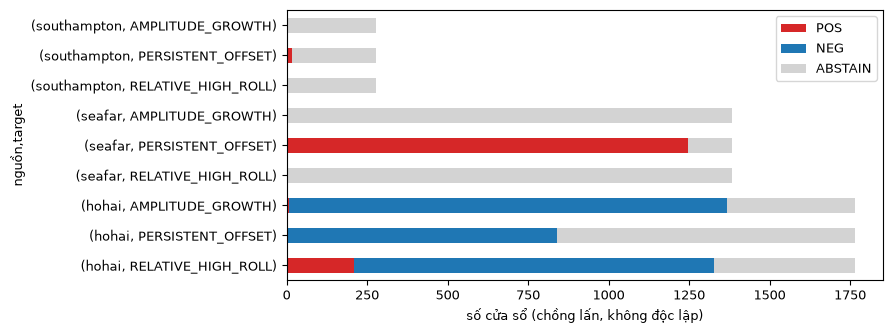

In [3]:
rows = []
for ds, r in summary["readiness"].items():
    for t, v in r["targets"].items():
        rows.append({"nguồn": ds, "target": t, "POS": v["positive_windows"], "NEG": v["negative_windows"], "ABSTAIN": v["abstain_windows"],
                     "nhóm POS": v["positive_groups"], "session POS": v["positive_sessions"], "quyết định": v["decision"], "lý do chặn": ", ".join(v["blockers"])})
ready = pd.DataFrame(rows); display(ready)
fig, ax = plt.subplots(figsize=(9, 3.4))
pivot = ready.set_index(["nguồn", "target"])[["POS", "NEG", "ABSTAIN"]]
pivot.plot(kind="barh", stacked=True, ax=ax, color=["tab:red", "tab:blue", "lightgray"])
ax.set_xlabel("số cửa sổ (chồng lấn, không độc lập)"); plt.tight_layout(); plt.show()

## Chồng lấn đa nhãn

In [4]:
display(data.groupby(["dataset_source", "proxy_phenotypes"]).size().rename("cửa sổ").reset_index())
multi = data[data.multi_label]
display(multi[["window_id", "session_id", "roll_std_60", "log_centered_std_ratio"]])

,dataset_source,proxy_phenotypes,cửa sổ
0,hohai,"[""RELATIVE_HIGH_ROLL"", ""AMPLITUDE_GROWTH""]",8
1,hohai,"[""RELATIVE_HIGH_ROLL""]",201
2,hohai,[],1555
3,seafar,"[""PERSISTENT_OFFSET""]",1246
4,seafar,[],138
5,southampton,"[""PERSISTENT_OFFSET""]",16
6,southampton,[],261


,window_id,session_id,roll_std_60,log_centered_std_ratio
35,hohai|Berth_B_T7_Type_A|segment_000|412.000000,Berth_B_T7_Type_A,0.505169,0.601066
36,hohai|Berth_B_T7_Type_A|segment_000|422.000000,Berth_B_T7_Type_A,0.539999,0.554494
37,hohai|Berth_B_T7_Type_A|segment_000|432.000000,Berth_B_T7_Type_A,0.549083,0.537352
1570,hohai|Berth_D_T8_Type_B|segment_000|642.000000,Berth_D_T8_Type_B,0.585667,0.616506
1571,hohai|Berth_D_T8_Type_B|segment_000|652.000000,Berth_D_T8_Type_B,0.586262,0.502137
1572,hohai|Berth_D_T8_Type_B|segment_000|662.000000,Berth_D_T8_Type_B,0.583312,0.523460
1735,hohai|Berth_D_T9_Type_A|segment_000|612.000000,Berth_D_T9_Type_A,0.655862,0.494072
1736,hohai|Berth_D_T9_Type_A|segment_000|622.000000,Berth_D_T9_Type_A,0.647976,0.466272


Mọi cửa sổ AMPLITUDE_GROWTH POS cũng là RELATIVE_HIGH_ROLL POS; cả hai cờ được giữ, không ép về một lớp.

## Độ phủ theo nhóm độc lập và session

In [5]:
h = data[data.dataset_source == "hohai"]
cov = pd.crosstab([h.experiment_group], h.RELATIVE_HIGH_ROLL_status)
cov2 = pd.crosstab([h.experiment_group], h.AMPLITUDE_GROWTH_status)
display(pd.concat({"RELATIVE_HIGH_ROLL": cov, "AMPLITUDE_GROWTH": cov2}, axis=1).fillna(0).astype(int))
display(pd.crosstab(h.session_id, h.RELATIVE_HIGH_ROLL_status))

RELATIVE_HIGH_ROLL           AMPLITUDE_GROWTH       \
RELATIVE_HIGH_ROLL_status            ABSTAIN  NEG  POS          ABSTAIN  NEG   
experiment_group                                                               
hohai|T1                                  12   72    0               16   68   
hohai|T2                                  12   72    0               20   64   
hohai|T3                                  36  216    0               51  201   
hohai|T4                                  12   72    0               17   67   
hohai|T5                                  12   72    0               24   60   
hohai|T6                                  41  211    0               57  195   
hohai|T7                                  59  166   27               48  201   
hohai|T8                                 171  113  136               92  325   
hohai|T9                                  82  124   46               71  179   

                               
RELATIVE_HIGH_ROLL_status POS  
experiment_group               
hohai|T1                    0  
hohai|T2                    0  
hohai|T3                    0  
hohai|T4                    0  
hohai|T5                    0  
hohai|T6                    0  
hohai|T7                    3  
hohai|T8                    3  
hohai|T9                    2

RELATIVE_HIGH_ROLL_status,ABSTAIN,NEG,POS
session_id,,,
Berth_B_T7_Type_A,15,64,5
Berth_B_T8_Type_A,25,44,15
Berth_B_T9_Type_A,12,72,0
Berth_C_T7_Type_A,12,72,0
Berth_C_T8_Type_A,43,24,17
Berth_C_T9_Type_A,42,36,6
Berth_D_T1_Type_A,12,72,0
Berth_D_T2_Type_A,12,72,0
Berth_D_T3_Type_A,12,72,0


## Bằng chứng chọn khóa nhóm: tương quan chéo Roll giữa 21 session Hohai

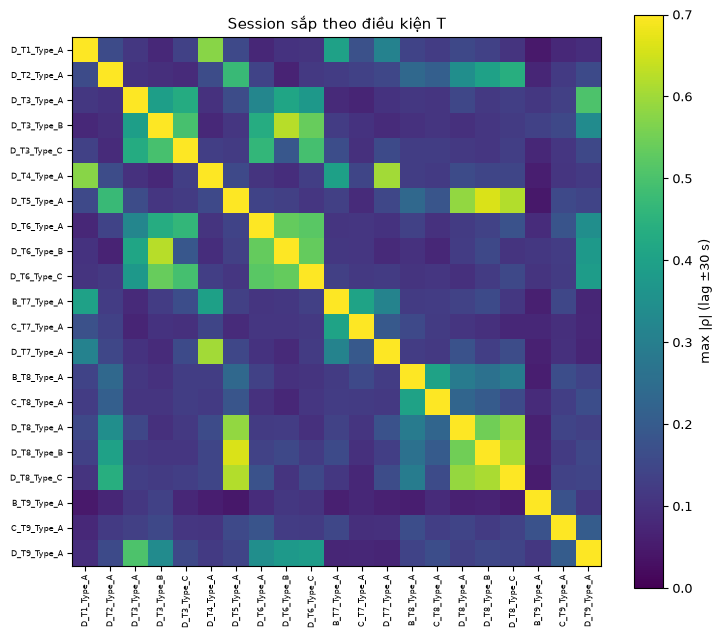

,count,mean,std,min,25%,50%,75%,max
same_condition,,,,,,,,
False,188.0,0.165101,0.124652,0.046378,0.103729,0.124545,0.154677,0.659429
True,22.0,0.359602,0.157061,0.114493,0.209954,0.353824,0.515291,0.612445


In [6]:
xc = pd.read_csv(PROXY / "hohai_session_xcorr.csv")
sessions = sorted(set(xc.session_a) | set(xc.session_b))
mat = pd.DataFrame(np.eye(len(sessions)), index=sessions, columns=sessions)
for r in xc.itertuples():
    mat.loc[r.session_a, r.session_b] = mat.loc[r.session_b, r.session_a] = r.max_abs_xcorr
order = sorted(sessions, key=lambda s: (int(s.split("_T")[1].split("_")[0]), s))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(mat.loc[order, order], cmap="viridis", vmin=0, vmax=0.7)
ax.set_xticks(range(len(order))); ax.set_xticklabels([s.replace("Berth_", "") for s in order], rotation=90, fontsize=6)
ax.set_yticks(range(len(order))); ax.set_yticklabels([s.replace("Berth_", "") for s in order], fontsize=6)
plt.colorbar(im, label="max |ρ| (lag ±30 s)"); ax.set_title("Session sắp theo điều kiện T"); plt.tight_layout(); plt.show()
display(xc.groupby("same_condition").max_abs_xcorr.describe())

## Support theo split (outer fold) cho target TRAINABLE

In [7]:
rf = json.loads((REPO_ROOT / "ml/reports/ml/rf_poc_results.json").read_text())
if rf.get("targets"):
    folds = rf["targets"]["RELATIVE_HIGH_ROLL"]["feature_sets"]["full_23"]["folds"]
    display(pd.DataFrame(folds)[["fold", "test_groups", "train_windows", "train_positive", "train_positive_groups", "test_windows", "test_positive", "test_abstain_windows"]])
else:
    print("Không có target TRAINABLE; không có split để báo cáo.")

,fold,test_groups,train_windows,train_positive,train_positive_groups,test_windows,test_positive,test_abstain_windows
0,0,[hohai|T1],1296,145,3,72,0,0
1,1,[hohai|T2],1296,145,3,72,0,0
2,2,[hohai|T3],1166,130,3,216,0,0
3,3,[hohai|T4],1296,145,3,72,0,0
4,4,[hohai|T5],1296,145,3,72,0,0
5,5,[hohai|T6],1166,130,3,211,0,5
6,6,[hohai|T7],1166,130,2,193,27,23
7,7,[hohai|T8],1037,116,3,249,136,111
8,8,[hohai|T9],1166,130,2,170,46,46


## Kết luận readiness

- Chỉ `RELATIVE_HIGH_ROLL` ở Hohai qua cổng (POS ở đúng 3 nhóm T7–T9).
- `AMPLITUDE_GROWTH`, `PERSISTENT_OFFSET` và mọi target ở Seafar/Southampton là NOT_TRAINABLE — không tạo nhãn giả, không gộp nguồn.

## Giải thích kỹ thuật phục vụ vấn đáp cá nhân

Số cửa sổ lớn không có nghĩa nhiều quan sát độc lập: 1.512 cửa sổ Hohai đầy đủ chỉ thuộc 9 điều kiện thử nghiệm. Cổng readiness đếm **nhóm**, không đếm cửa sổ.